<a href="https://colab.research.google.com/github/MakhloufiMahdi/customer-churn-intelligence-platform/blob/main/notebooks/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
## 2. Data Source and Collection

Dataset: IBM Telco Customer Churn

Source:
https://github.com/IBM/telco-customer-churn-on-icp4d

Format: CSV
Expected records: 7,043
Expected columns: 21

The original dataset will remain unchanged.

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (3761609482.py, line 9)

In [6]:
from pathlib import Path
import requests
import hashlib

# Create project directories in Colab
BASE_DIR = Path("/content/customer-churn-intelligence-platform")

RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Dataset source
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

RAW_FILE = RAW_DIR / "Telco-Customer-Churn.csv"

# Download dataset
response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

RAW_FILE.write_bytes(response.content)

print("Download successful!")
print("File:", RAW_FILE)
print("Size:", round(RAW_FILE.stat().st_size / 1024, 2), "KB")

Download successful!
File: /content/customer-churn-intelligence-platform/data/raw/Telco-Customer-Churn.csv
Size: 947.71 KB


In [7]:
sha256_hash = hashlib.sha256(
    RAW_FILE.read_bytes()
).hexdigest()

EXPECTED_HASH = (
    "16320c9c1ec72448db59aa0a26a0b954"
    "01046bef5d02fd3aeb906448e3055e91"
)

print("SHA-256:", sha256_hash)
print("Integrity check:", sha256_hash == EXPECTED_HASH)

assert sha256_hash == EXPECTED_HASH, (
    "Dataset integrity verification failed!"
)

SHA-256: 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91
Integrity check: True


In [8]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv(RAW_FILE)

print("Dataset successfully loaded.")
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

display(df_raw.head())

Dataset successfully loaded.
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df_raw.info()

In [11]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
for index, column in enumerate(df_raw.columns, start=1):
    print(index, column)

1 customerID
2 gender
3 SeniorCitizen
4 Partner
5 Dependents
6 tenure
7 PhoneService
8 MultipleLines
9 InternetService
10 OnlineSecurity
11 OnlineBackup
12 DeviceProtection
13 TechSupport
14 StreamingTV
15 StreamingMovies
16 Contract
17 PaperlessBilling
18 PaymentMethod
19 MonthlyCharges
20 TotalCharges
21 Churn


In [14]:
missing_report = pd.DataFrame({
    "missing_values": df_raw.isna().sum(),
    "blank_strings": df_raw.select_dtypes(
        include="object"
    ).apply(
        lambda col: col.astype(str).str.strip().eq("").sum()
    ),
    "unique_values": df_raw.nunique()
})

display(missing_report)

,missing_values,blank_strings,unique_values
Churn,0,0.0,2
Contract,0,0.0,3
Dependents,0,0.0,2
DeviceProtection,0,0.0,3
InternetService,0,0.0,3
MonthlyCharges,0,NaN,1585
MultipleLines,0,0.0,3
OnlineBackup,0,0.0,3
OnlineSecurity,0,0.0,3
PaperlessBilling,0,0.0,2


In [15]:
print(
    "Duplicate rows:",
    df_raw.duplicated().sum()
)

print(
    "Duplicate customer IDs:",
    df_raw["customerID"].duplicated().sum()
)

print(
    "Unique customers:",
    df_raw["customerID"].nunique()
)

Duplicate rows: 0
Duplicate customer IDs: 0
Unique customers: 7043


In [16]:
total_charges_numeric = pd.to_numeric(
    df_raw["TotalCharges"].str.strip(),
    errors="coerce"
)

print(
    "TotalCharges invalid or blank:",
    total_charges_numeric.isna().sum()
)

print(
    "Customers with tenure = 0:",
    (df_raw["tenure"] == 0).sum()
)

display(
    df_raw.loc[
        total_charges_numeric.isna(),
        ["customerID", "tenure", "TotalCharges"]
    ].head(15)
)

TotalCharges invalid or blank: 11
Customers with tenure = 0: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [17]:
churn_counts = df_raw["Churn"].value_counts()

churn_percentages = (
    df_raw["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_report = pd.DataFrame({
    "customers": churn_counts,
    "percentage": churn_percentages
})

display(churn_report)

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


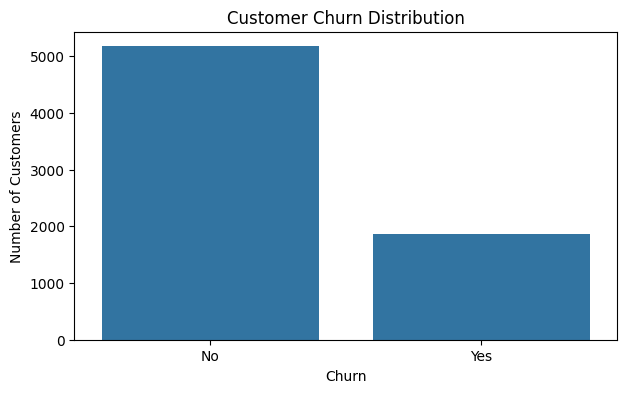

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df_raw,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
data_summary = {
    "dataset_name": "IBM Telco Customer Churn",
    "rows": df_raw.shape[0],
    "columns": df_raw.shape[1],
    "duplicate_rows": int(df_raw.duplicated().sum()),
    "duplicate_customer_ids": int(
        df_raw["customerID"].duplicated().sum()
    ),
    "missing_values": int(df_raw.isna().sum().sum()),
    "blank_total_charges": int(
        df_raw["TotalCharges"].str.strip().eq("").sum()
    ),
    "churn_rate": round(
        (df_raw["Churn"] == "Yes").mean() * 100, 2
    )
}

display(pd.Series(data_summary))

,0
dataset_name,IBM Telco Customer Churn
rows,7043
columns,21
duplicate_rows,0
duplicate_customer_ids,0
missing_values,0
blank_total_charges,11
churn_rate,26.54
